# Book Recommendation Engine | Project 2

**Juan Luna Santibanez**  
Miami Dade College · CAI2100C-2267-6908 · Machine Learning Foundations  
Professor Beth Muturi

## My goal

I developed a practical recommendation engine for books, following the six stages of the AI project cycle introduced in class. I compare two methods: **content-based filtering** (similar book information) and **collaborative filtering** (patterns in readers' ratings). I also explain how I evaluate the results.

I use three Book-Crossing data files: `Books.csv`, `Ratings.csv`, and `Users.csv`. The recommendation methods work on the same collection but answer different questions.

**Data origin:** If my classroom CSV files are present, the notebook uses them. Otherwise, it retrieves a public Book-Crossing copy referenced in Microsoft Learn. That public source is not represented as an instructor-provided file. All charts and model metrics below are computed during notebook execution.

## 1. Understanding the problem

**Question:** How can I help a reader discover books that match an interest or resemble books appreciated by other readers?

My content-based model uses a book's title, author, publisher, and publication year. My collaborative model learns from explicit user-book ratings. A zero in Book-Crossing means an *implicit interaction*, **not** a rating of zero stars. I therefore use ratings from 1 to 10 for the numerical evaluation.

The goal is an educational recommendation engine, not a commercial production service. No personal identifiers or demographics are displayed in the web demonstration.

## 2. Data acquisition and preparation

I load the CSV files and check their columns before any modeling. If I open this notebook directly in Google Colab, the data loader downloads the public files only when local files are missing.

In [1]:
import json
import sys
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.sparse import csr_matrix

RANDOM_STATE = 42
FOLDER = Path('data')
FILES = ['Books.csv', 'Ratings.csv', 'Users.csv']
PUBLIC_SOURCE = 'https://synapseaisolutionsa.z13.web.core.windows.net/data/Book-Recommendation-Dataset'
REPO_SOURCE = 'https://raw.githubusercontent.com/SupaHumano/CAI2100C-Book-Recommendation-Engine/main/data'

def find_file(filename):
    locations = [FOLDER / filename, Path(filename), Path('..') / 'data' / filename,
                 Path('/content') / filename, Path('/content/data') / filename]
    for p in locations:
        if p.is_file():
            return p
    # The public files are downloaded only if the classroom copy is unavailable.
    FOLDER.mkdir(exist_ok=True)
    target = FOLDER / filename
    for base in (PUBLIC_SOURCE,):
        try:
            url = f'{base}/{filename}'
            request = urllib.request.Request(url, headers={'User-Agent': 'CAI2100C-academic-notebook'})
            with urllib.request.urlopen(request, timeout=90) as src, target.open('wb') as dst:
                while True:
                    block = src.read(1024 * 1024)
                    if not block: break
                    dst.write(block)
            if target.stat().st_size < 1000:
                raise ValueError('Downloaded file is unexpectedly small')
            print(f'Downloaded {filename} from the public Book-Crossing data source.')
            return target
        except Exception as exc:
            target.unlink(missing_ok=True)
            print(f'Unable to download {filename}: {type(exc).__name__}')
    raise FileNotFoundError(f'Place {filename} in the data/ directory, then run the notebook again.')

def read_bookcrossing_csv(path):
    # The public cleaned copy uses commas. The original Book-Crossing files may use semicolons.
    df = pd.read_csv(path, encoding='latin-1', sep=',', dtype={'ISBN': str}, on_bad_lines='skip', low_memory=False)
    if len(df.columns) == 1:
        df = pd.read_csv(path, encoding='latin-1', sep=';', dtype={'ISBN': str}, on_bad_lines='skip', low_memory=False)
    df.columns = df.columns.astype(str).str.strip().str.replace('"', '', regex=False)
    return df

books_raw = read_bookcrossing_csv(find_file(FILES[0]))
ratings_raw = read_bookcrossing_csv(find_file(FILES[1]))
users_raw = read_bookcrossing_csv(find_file(FILES[2]))
expected = {'books': {'ISBN','Book-Title','Book-Author','Publisher','Year-Of-Publication'},
            'ratings': {'User-ID','ISBN','Book-Rating'},
            'users': {'User-ID','Location','Age'}}
for label, frame in [('books',books_raw),('ratings',ratings_raw),('users',users_raw)]:
    missing = expected[label] - set(frame.columns)
    if missing:
        raise ValueError(f'{label} CSV is missing required fields: {sorted(missing)}')
summary = pd.DataFrame({'File': FILES,
                       'Records': [len(books_raw),len(ratings_raw),len(users_raw)],
                       'Columns': [len(books_raw.columns),len(ratings_raw.columns),len(users_raw.columns)]})
display(summary)
display(books_raw[['ISBN','Book-Title','Book-Author']].head(3))

Downloaded Books.csv from the public Book-Crossing data source.


Downloaded Ratings.csv from the public Book-Crossing data source.


Downloaded Users.csv from the public Book-Crossing data source.


,File,Records,Columns
0,Books.csv,271360,8
1,Ratings.csv,1149780,3
2,Users.csv,278858,3


,ISBN,Book-Title,Book-Author
0,0195153448,Classical Mythology,Mark P. O. Morford
1,0002005018,Clara Callan,Richard Bruce Wright
2,0060973129,Decision in Normandy,Carlo D'Este


In [2]:
books = books_raw.copy()
ratings = ratings_raw.copy()
users = users_raw.copy()
for frame in (books,ratings):
    frame['ISBN'] = frame['ISBN'].astype(str).str.strip()
books = books.dropna(subset=['ISBN','Book-Title','Book-Author']).drop_duplicates('ISBN')
for key in ('Book-Title','Book-Author','Publisher'):
    books[key] = books[key].fillna('Unknown').astype(str).str.strip()
books['Year-Of-Publication'] = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
books.loc[~books['Year-Of-Publication'].between(1450, 2026),'Year-Of-Publication'] = np.nan
ratings['User-ID'] = pd.to_numeric(ratings['User-ID'], errors='coerce')
ratings['Book-Rating'] = pd.to_numeric(ratings['Book-Rating'], errors='coerce')
ratings = ratings.dropna(subset=['User-ID','ISBN','Book-Rating'])
ratings = ratings[ratings['Book-Rating'].between(0,10)].copy()
ratings['User-ID'] = ratings['User-ID'].astype('int32')
ratings = ratings.drop_duplicates(['User-ID','ISBN'],keep='last')
users['User-ID'] = pd.to_numeric(users['User-ID'],errors='coerce')
users['Age'] = pd.to_numeric(users['Age'],errors='coerce')
users.loc[~users['Age'].between(5,100),'Age'] = np.nan
users = users.dropna(subset=['User-ID']).drop_duplicates('User-ID')
explicit = ratings[ratings['Book-Rating'] > 0].merge(
    books[['ISBN','Book-Title','Book-Author','Publisher']],on='ISBN',how='inner')
print('Known books:',f'{len(books):,}','| Readers:',f'{len(users):,}',
      '| All interactions:',f'{len(ratings):,}',
      '| Explicit ratings linked to known books:',f'{len(explicit):,}',
      '| Implicit interactions (0):',f'{int((ratings["Book-Rating"] == 0).sum()):,}')
assert len(explicit) > 10, 'At least 11 explicit ratings are needed to run the model.'

Known books: 271,357 | Readers: 278,858 | All interactions: 1,149,780 | Explicit ratings linked to known books: 383,841 | Implicit interactions (0): 716,109


## 3. Exploratory data analysis (EDA)

I inspect the 20 most highly rated books and authors with a minimum number of explicit reviews. This prevents a single score of 10 from being treated as stronger evidence than many consistent reviews. The number of ratings is displayed next to each average.

In [3]:
book_stats = (explicit.groupby(['ISBN','Book-Title','Book-Author'],as_index=False)
              .agg(average_rating=('Book-Rating','mean'),rating_count=('Book-Rating','size')))
threshold_books = 25 if len(explicit)>1000 else 1
eligible_books = book_stats[book_stats.rating_count >= threshold_books]
if eligible_books.empty: eligible_books = book_stats
best_books = eligible_books.sort_values(['average_rating','rating_count'],ascending=[False,False]).head(20)
author_stats = (explicit.groupby('Book-Author',as_index=False)
                .agg(average_rating=('Book-Rating','mean'),rating_count=('Book-Rating','size')))
threshold_authors = 50 if len(explicit)>1000 else 1
eligible_authors = author_stats[author_stats.rating_count >= threshold_authors]
if eligible_authors.empty: eligible_authors = author_stats
best_authors = eligible_authors.sort_values(['average_rating','rating_count'],ascending=[False,False]).head(20)
print(f'Book threshold: {threshold_books} explicit ratings; author threshold: {threshold_authors}.')
display(best_books[['Book-Title','Book-Author','average_rating','rating_count']].round(2))
display(best_authors[['Book-Author','average_rating','rating_count']].round(2))

Book threshold: 25 explicit ratings; author threshold: 50.


,Book-Title,Book-Author,average_rating,rating_count
71460,"The Two Towers (The Lord of the Rings, Part 2)",J. R. R. Tolkien,9.72,25
9385,84 Charing Cross Road,Helene Hanff,9.46,28
24538,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,9.40,77
2721,Where the Sidewalk Ends : Poems and Drawings,Shel Silverstein,9.40,25
40942,The Cat in the Hat,Dr. Seuss,9.31,32
114251,Love You Forever,Robert N. Munsch,9.28,25
46135,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,9.26,137
103957,Weirdos From Another Planet!,Bill Watterson,9.24,25
75948,Lonesome Dove,Larry McMurtry,9.21,33
46428,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,9.21,53


,Book-Author,average_rating,rating_count
40833,Maud Hart Lovelace,9.29,52
3857,Art Spiegelman,9.24,50
5908,Bill Watterson,9.19,333
15096,Dr. Seuss,9.18,207
54258,Shel Silverstein,9.16,126
3519,Antoine de Saint-ExupÃÂ©ry,9.03,171
6391,Bradley Trevor Greive,8.99,84
22241,Harper Lee,8.99,281
24488,J. K. Rowling,8.97,1746
10122,Clamp,8.96,109


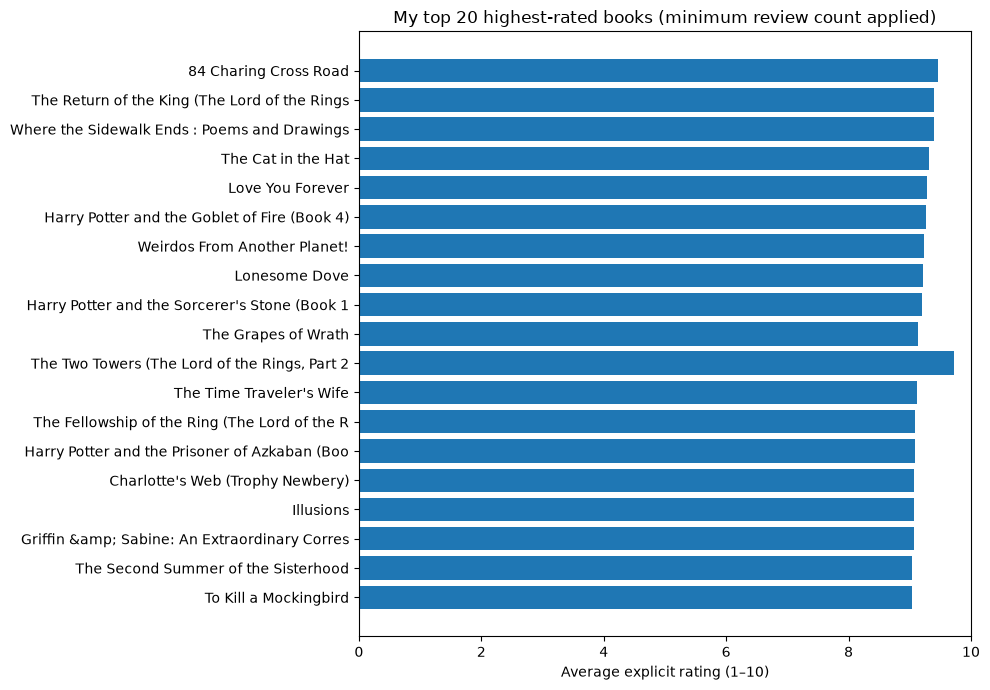

/tmp/ipykernel_2415/3847703570.py:17: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2415/3847703570.py:18: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.savefig('assets/top-authors.svg',bbox_inches='tight') if Path('assets').exists() else None
/tmp/ipykernel_2415/3847703570.py:19: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.savefig('assets/top-authors.png',bbox_inches='tight',dpi=140) if Path('assets').exists() else None


/opt/hostedtoolcache/Python/3.11.17/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


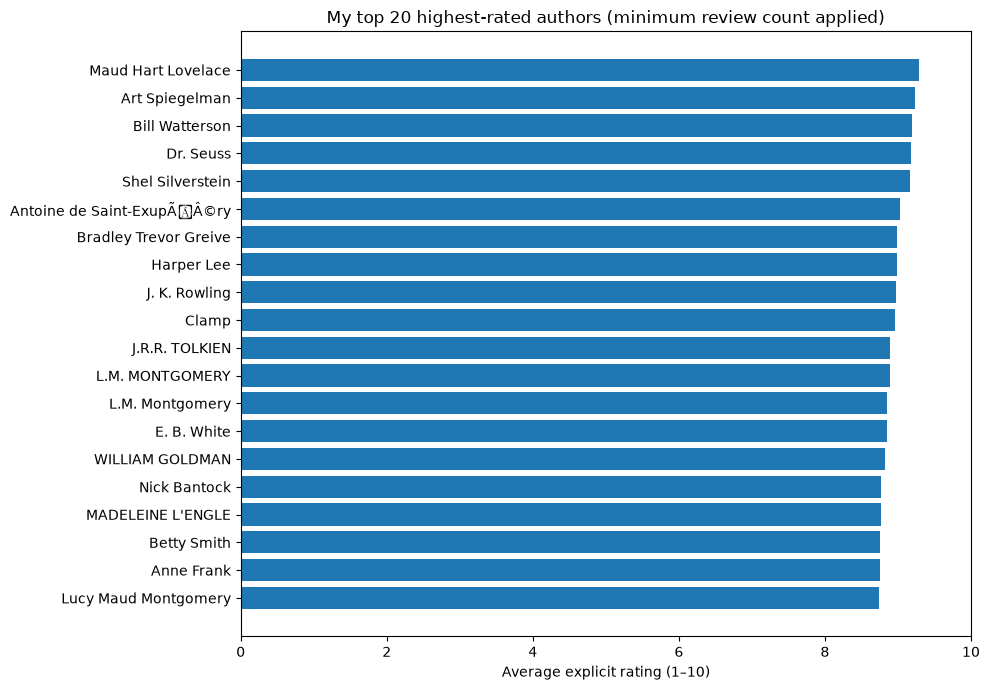

In [4]:
fig, ax = plt.subplots(figsize=(10,7))
chart = best_books.iloc[::-1]
ax.barh(chart['Book-Title'].str.slice(0,45),chart['average_rating'])
ax.set_xlim(0,10)
ax.set_xlabel('Average explicit rating (1–10)')
ax.set_title('My top 20 highest-rated books (minimum review count applied)')
fig.tight_layout()
fig.savefig('assets/top-books.svg',bbox_inches='tight') if Path('assets').exists() else None
fig.savefig('assets/top-books.png',bbox_inches='tight',dpi=140) if Path('assets').exists() else None
plt.show()
fig, ax = plt.subplots(figsize=(10,7))
chart = best_authors.iloc[::-1]
ax.barh(chart['Book-Author'].str.slice(0,45),chart['average_rating'])
ax.set_xlim(0,10)
ax.set_xlabel('Average explicit rating (1–10)')
ax.set_title('My top 20 highest-rated authors (minimum review count applied)')
fig.tight_layout()
fig.savefig('assets/top-authors.svg',bbox_inches='tight') if Path('assets').exists() else None
fig.savefig('assets/top-authors.png',bbox_inches='tight',dpi=140) if Path('assets').exists() else None
plt.show()

## 4. Model A — Content-Based Filtering

I represent book metadata as a TF-IDF text vector and use cosine similarity to retrieve related items. This is not based on users' ratings. Book-Crossing does not provide reliable full book descriptions or genres, so I do not invent them.

In [5]:
counts = explicit.groupby('ISBN').size()
min_count = 8 if len(books)>1000 else 1
candidates = books[books.ISBN.isin(counts[counts>=min_count].index)].copy()
if len(candidates)<8:
    candidates = books[books.ISBN.isin(counts.index)].copy()
# A bounded candidate catalog makes TF-IDF practical on a classroom laptop.
candidates['interest_count'] = candidates.ISBN.map(counts).fillna(0)
candidates = candidates.sort_values(['interest_count','ISBN'],ascending=[False,True]).head(6000).reset_index(drop=True)

def book_text(row):
    return ' '.join([str(row['Book-Title']),str(row['Book-Author']),
                     str(row['Book-Author']),str(row['Publisher']),
                     str(int(row['Year-Of-Publication'])) if pd.notna(row['Year-Of-Publication']) else ''])
text_features = candidates.apply(book_text,axis=1)
vectorizer = TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=12000,
                             min_df=2 if len(candidates)>=100 else 1)
feature_matrix = vectorizer.fit_transform(text_features)

def content_recommend(isbn,n=5):
    matched = candidates.index[candidates.ISBN.eq(str(isbn))]
    if len(matched)==0: raise ValueError(f'ISBN not found in content candidate catalog: {isbn}')
    index=int(matched[0])
    scores=linear_kernel(feature_matrix[index],feature_matrix).ravel()
    order=np.argsort(-scores,kind='stable')
    order=[i for i in order if i!=index and scores[i]>0][:n]
    result=candidates.loc[order,['ISBN','Book-Title','Book-Author']].copy()
    result['cosine_similarity']=np.round(scores[order],4)
    return result.reset_index(drop=True)

popular_seeds = candidates.head(min(5,len(candidates)))
anchor = str(popular_seeds.iloc[0]['ISBN'])
print('My example input:',popular_seeds.iloc[0]['Book-Title'])
content_example=content_recommend(anchor,5)
display(content_example)
print('Candidate books:',len(candidates),'| TF-IDF features:',feature_matrix.shape[1])

My example input: The Lovely Bones: A Novel


,ISBN,Book-Title,Book-Author,cosine_similarity
0,0316168815,The Lovely Bones,Alice Sebold,0.7841
1,0684857820,Lucky,Alice Sebold,0.7025
2,0316096199,Lucky : A Memoir,Alice Sebold,0.6643
3,0688177867,The Book Borrower: A Novel,Alice Mattison,0.3454
4,0553581295,Darkness Peering,Alice Blanchard,0.2376


Candidate books: 6000 | TF-IDF features: 10662


## 5. Model B — Collaborative Filtering

I use **item-item collaborative filtering**. Instead of matching title words, the model compares patterns of ratings from readers who have rated the same books. I split observations into training and testing before fitting the similarity model. To keep the sparse matrix feasible on a student laptop, I restrict this experiment to frequently rated books and active readers, and I report that selection.

In [6]:
# Select a documented, manageable collaborative subset.
book_freq=explicit.groupby('ISBN').size().sort_values(ascending=False)
selected=explicit[explicit.ISBN.isin(book_freq.head(1500).index)][['User-ID','ISBN','Book-Rating']].copy()
reader_freq=selected.groupby('User-ID').size()
min_reader=5 if len(explicit)>1000 else 2
selected=selected[selected['User-ID'].isin(reader_freq[reader_freq>=min_reader].index)]
selected=selected.drop_duplicates(['User-ID','ISBN'])
assert len(selected)>=20, 'Not enough linked ratings for collaborative validation.'
train,test=train_test_split(selected,test_size=0.2,random_state=RANDOM_STATE)
all_users=np.sort(train['User-ID'].unique())
all_items=np.sort(train['ISBN'].unique())
user_index={k:i for i,k in enumerate(all_users)}
item_index={k:i for i,k in enumerate(all_items)}
rr=train['ISBN'].map(item_index).to_numpy()
cc=train['User-ID'].map(user_index).to_numpy()
values=train['Book-Rating'].to_numpy(dtype=float)
item_user=csr_matrix((values,(rr,cc)),shape=(len(all_items),len(all_users)))
neighbor_count=min(21,len(all_items))
model=NearestNeighbors(metric='cosine',algorithm='brute',n_neighbors=neighbor_count)
model.fit(item_user)
distances,neighbors=model.kneighbors(item_user,return_distance=True)
neighbor_map={isbn:[(str(all_items[j]),float(max(0,1-d)))
                     for j,d in zip(neighbors[i],distances[i]) if j!=i and d<1]
              for i,isbn in enumerate(all_items)}
user_train={int(uid):dict(zip(df.ISBN.astype(str),df['Book-Rating'].astype(float)))
            for uid,df in train.groupby('User-ID')}
item_mean=train.groupby('ISBN')['Book-Rating'].mean().to_dict()
mean_all=float(train['Book-Rating'].mean())

def collaborative_predict(user_id,isbn):
    history=user_train.get(int(user_id),{})
    matches=[(weight,history[neighbor]) for neighbor,weight in neighbor_map.get(str(isbn),[])
             if neighbor in history and weight>0]
    if matches:
        numerator=sum(weight*rating for weight,rating in matches)
        denominator=sum(weight for weight,rating in matches)
        return float(np.clip(numerator/denominator,1,10)),True
    return float(item_mean.get(str(isbn),mean_all)),False

validation=test[test['User-ID'].isin(all_users)&test['ISBN'].isin(all_items)].copy()
assert len(validation)>0, 'No known user/book pairs remain for validation.'
actual=validation['Book-Rating'].to_numpy(dtype=float)
predicted=[]; personal=[]
for row in validation.itertuples(index=False):
    estimate,matched=collaborative_predict(row[0],row[1])
    predicted.append(estimate);personal.append(matched)
predicted=np.array(predicted)
item_baseline=np.array([item_mean.get(k,mean_all) for k in validation['ISBN']])
collab_mae=float(mean_absolute_error(actual,predicted))
collab_rmse=float(np.sqrt(mean_squared_error(actual,predicted)))
baseline_mae=float(mean_absolute_error(actual,item_baseline))
baseline_rmse=float(np.sqrt(mean_squared_error(actual,item_baseline)))
coverage=float(np.mean(personal))
comparison=pd.DataFrame({'Method':['Item-based collaborative (with fallback)','Book-mean baseline'],
                          'MAE':[collab_mae,baseline_mae],
                          'RMSE':[collab_rmse,baseline_rmse]})
print('Selected explicit ratings:',f'{len(selected):,}',
      '| Training:',f'{len(train):,}','| Test:',f'{len(test):,}',
      '| Evaluated known pairs:',f'{len(validation):,}',
      '| Neighbor-supported predictions:',f'{coverage:.1%}')
display(comparison.round(4))

Selected explicit ratings: 45,645 | Training: 36,516 | Test: 9,129 | Evaluated known pairs: 9,129 | Neighbor-supported predictions: 40.9%


,Method,MAE,RMSE
0,Item-based collaborative (with fallback),1.2470,1.7179
1,Book-mean baseline,1.3338,1.7126


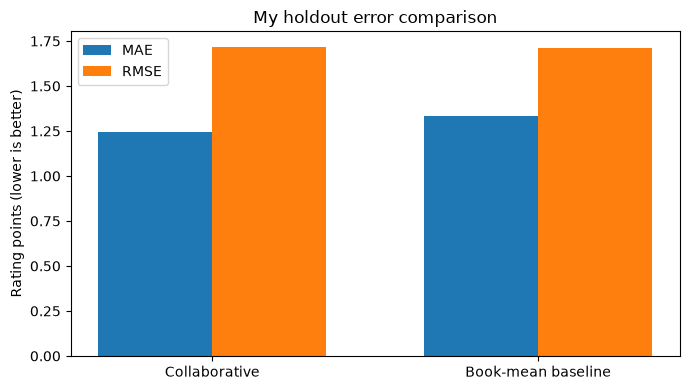

In [7]:
fig,ax=plt.subplots(figsize=(7,4))
xs=np.arange(2);width=.35
ax.bar(xs-width/2,comparison.MAE,width,label='MAE')
ax.bar(xs+width/2,comparison.RMSE,width,label='RMSE')
ax.set_xticks(xs, ['Collaborative','Book-mean baseline'])
ax.set_ylabel('Rating points (lower is better)')
ax.set_title('My holdout error comparison')
ax.legend()
fig.tight_layout()
fig.savefig('assets/model-comparison.svg',bbox_inches='tight') if Path('assets').exists() else None
fig.savefig('assets/model-comparison.png',bbox_inches='tight',dpi=140) if Path('assets').exists() else None
plt.show()

## 6. Example recommendations and what I learned

My content-based system compares characteristics of books. My collaborative system uses user-rating patterns. I show both, and I evaluate the collaborative method against a simple baseline. A method does **not** count as better just because it sounds more advanced: its actual test error matters.

In [8]:
# Recommend new items for one active reader using the model fitted on training data.
example_user=max(user_train,key=lambda uid:len(user_train[uid]))
history=user_train[example_user]
candidate_items=[isbn for isbn in all_items if isbn not in history]
scored=[]
for isbn in candidate_items:
    estimate,matched=collaborative_predict(example_user,isbn)
    if matched:scored.append((str(isbn),estimate))
scored.sort(key=lambda item:(-item[1],item[0]))
collab_results=pd.DataFrame(scored[:8],columns=['ISBN','Estimated rating'])
collab_results=collab_results.merge(books[['ISBN','Book-Title','Book-Author']],on='ISBN',how='left')
print('Reader example: an anonymized user with',len(history),'known training ratings.')
display(collab_results[['Book-Title','Book-Author','Estimated rating']].round(2))

Reader example: an anonymized user with 638 known training ratings.


,Book-Title,Book-Author,Estimated rating
0,The Wide Window (A Series of Unfortunate Event...,Lemony Snicket,9.80
1,What to Expect When You're Expecting (Revised ...,Arlene Eisenberg,9.49
2,The Hobbit : The Enchanting Prelude to The Lor...,J.R.R. TOLKIEN,9.41
3,"Assassins: Assignment: Jerusalem, Target: Anti...",Tim Lahaye,9.30
4,Tears of the Moon (Irish Trilogy),Nora Roberts,9.29
5,Beloved (Plume Contemporary Fiction),Toni Morrison,9.23
6,The Dress Lodger (Ballantine Reader's Circle),Sheri Holman,9.18
7,Once upon a More Enlightened Time: More Politi...,James Finn Garner,9.17


## 7. Conclusion, limitations and responsible use

I found that **content-based filtering** can explain recommendations using metadata even when a book has few ratings. **Collaborative filtering** can capture reader preferences but struggles with new readers and rarely rated books. I separate implicit feedback (0) from explicit ratings (1–10), report sample sizes and compare held-out errors with a baseline. My results are based on the source CSV files and an educational subset; they are not evidence of commercial production accuracy.

**Data source:** Book-Crossing, Ziegler et al. (2005), linked through [GroupLens](https://grouplens.org/datasets/book-crossing/) and the three-file public example documented in [Microsoft Learn](https://learn.microsoft.com/en-us/fabric/data-science/retail-recommend-model). I used the instructor's conceptual workflow and the `Books`/`Ratings`/`Users` format discussed in class. I do not claim the public download is byte-for-byte identical to an unavailable course ZIP.

In [9]:
# Export measured results for my optional GitHub Pages learning lab.
# This is written only when the full notebook has actually run.
if Path('assets').exists():
    charts_available = all((Path('assets') / name).is_file() for name in
        ['top-books.png','top-authors.png','model-comparison.png'])
else:
    charts_available = False
project_results = {
    'data_source': 'Book-Crossing (local class files if present; otherwise the Microsoft Learn public copy)',
    'raw_counts': {row.File:int(row.Records) for row in summary.itertuples()},
    'explicit_linked': int(len(explicit)),
    'implicit_interactions': int((ratings['Book-Rating']==0).sum()),
    'content_candidate_books': int(len(candidates)),
    'collaborative_training_rows': int(len(train)),
    'collaborative_test_rows': int(len(test)),
    'collaborative_evaluable_rows': int(len(validation)),
    'collaborative_neighbor_coverage': round(coverage,4),
    'collaborative_MAE': round(collab_mae,4),
    'collaborative_RMSE': round(collab_rmse,4),
    'baseline_MAE': round(baseline_mae,4),
    'baseline_RMSE': round(baseline_rmse,4),
    'top_books': [{'title':str(row['Book-Title']),'author':str(row['Book-Author']),
                   'rating':round(float(row['average_rating']),2),'count':int(row['rating_count'])}
                  for _,row in best_books.iterrows()],
    'top_authors': [{'author':str(row['Book-Author']),'rating':round(float(row['average_rating']),2),
                     'count':int(row['rating_count'])} for _,row in best_authors.iterrows()],
    'content_examples': [],
    'collaborative_examples': [{'title':str(row['Book-Title']),'author':str(row['Book-Author']),
                               'predicted':round(float(row['Estimated rating']),2)}
                              for _,row in collab_results.iterrows()],
    'graphs_saved': charts_available,
}
for _,seed in popular_seeds.iterrows():
    recs=content_recommend(str(seed['ISBN']),5)
    project_results['content_examples'].append({
        'seed':str(seed['Book-Title']),
        'matches':[{'title':str(row['Book-Title']),'author':str(row['Book-Author']),
                    'score':float(row['cosine_similarity'])} for _,row in recs.iterrows()]})
if Path('data').exists():
    text=json.dumps(project_results,ensure_ascii=True,indent=2)
    (Path('data')/'results.json').write_text(text,encoding='utf-8')
    (Path('data')/'results.js').write_text('window.BOOK_ENGINE_RESULTS = '+json.dumps(project_results,ensure_ascii=True)+';\n',encoding='utf-8')
    print('I saved my measured figures and website data in assets/ and data/.')
print('Done. Both approaches and their recorded evaluation finished.')

I saved my measured figures and website data in assets/ and data/.
Done. Both approaches and their recorded evaluation finished.
